# NUMBER GUESSING GAME
## History & Statistical Analysis

**Submitted By:** Foram Brahmbhatt

**IU Number:** IU2441230467

**Course:** Bachelor of Technology - Computer Science and Engineering

**Institute:** Institute of Technology and Engineering, Indus University

**Academic Year:** 2026

---

## Project Objective

This project develops a Number Guessing Game application that records
the number of attempts required by players in each round.

The stored game history is analyzed to calculate:

- Total games
- Successful and failed games
- Success rate
- Average attempts
- Minimum and maximum attempts
- Player comparisons
- Period-wise performance
- Attempt patterns

## Technologies Used

- Python
- NumPy
- Pandas
- CSV File Handling
- User-defined modules
- Tkinter
- Matplotlib
- Input Validation
- Exception Handling

In [ ]:
import os
import random
import csv
import math
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("All required libraries imported successfully!")

All required libraries imported successfully!


In [ ]:
import os

PROJECT_FOLDER = "number_guessing_project"

os.makedirs(PROJECT_FOLDER, exist_ok=True)

CSV_FILE = os.path.join(
    PROJECT_FOLDER,
    "game_history.csv"
)

print("Project folder created successfully!")
print("Project folder:", PROJECT_FOLDER)
print("CSV file:", CSV_FILE)

Project folder created successfully!
Project folder: number_guessing_project
CSV file: number_guessing_project/game_history.csv


In [ ]:
%%writefile game_engine.py

import random
from datetime import datetime


def generate_target(low=1, high=100):
    """Generate a random target number."""
    return random.randint(low, high)


def check_guess(guess, target):
    """Check whether the guess is correct, too low, or too high."""

    if guess == target:
        return "Correct"

    elif guess < target:
        return "Too Low"

    else:
        return "Too High"


def calculate_score(attempts, success):
    """Calculate the player's score."""

    if not success:
        return 0

    score = max(100 - (attempts - 1) * 10, 10)

    return score


def create_game_record(
    game_id,
    player,
    target,
    attempts,
    result,
    score
):
    """Create one game record."""

    return {
        "Game_ID": game_id,
        "Player": player,
        "Date": datetime.now().strftime("%Y-%m-%d"),
        "Target": target,
        "Attempts": attempts,
        "Result": result,
        "Score": score
    }


print("game_engine.py created successfully!")

Overwriting game_engine.py


In [ ]:
%%writefile storage.py

import os
import pandas as pd


COLUMNS = [
    "Game_ID",
    "Player",
    "Date",
    "Target",
    "Attempts",
    "Result",
    "Score"
]


def initialize_file(filename):
    """Create the CSV file if it does not exist."""

    if not os.path.exists(filename):
        pd.DataFrame(columns=COLUMNS).to_csv(
            filename,
            index=False
        )


def load_games(filename):
    """Load game history from CSV."""

    initialize_file(filename)

    try:
        df = pd.read_csv(filename)

        if not df.empty:
            df["Game_ID"] = pd.to_numeric(
                df["Game_ID"],
                errors="coerce"
            )

            df["Attempts"] = pd.to_numeric(
                df["Attempts"],
                errors="coerce"
            )

            df["Score"] = pd.to_numeric(
                df["Score"],
                errors="coerce"
            )

        return df

    except Exception as e:
        print("Error loading file:", e)

        return pd.DataFrame(columns=COLUMNS)


def save_game(filename, record):
    """Save one game record."""

    initialize_file(filename)

    new_record = pd.DataFrame([record])

    new_record.to_csv(
        filename,
        mode="a",
        header=False,
        index=False
    )


def get_next_game_id(filename):
    """Get the next Game ID."""

    df = load_games(filename)

    if df.empty:
        return 1

    return int(df["Game_ID"].max()) + 1


def update_game(filename, game_id, updates):
    """Update an existing game record."""

    df = load_games(filename)

    if game_id not in df["Game_ID"].values:
        return False

    for key, value in updates.items():

        if key in df.columns:
            df.loc[
                df["Game_ID"] == game_id,
                key
            ] = value

    df.to_csv(
        filename,
        index=False
    )

    return True


def delete_game(filename, game_id):
    """Delete a game record."""

    df = load_games(filename)

    if game_id not in df["Game_ID"].values:
        return False

    df = df[
        df["Game_ID"] != game_id
    ]

    df.to_csv(
        filename,
        index=False
    )

    return True


print("storage.py created successfully!")

Writing storage.py


In [ ]:
%%writefile analytics.py

import pandas as pd
import numpy as np


def calculate_statistics(df):
    """Calculate overall game statistics."""

    if df.empty:
        return {}

    total_games = len(df)

    successful_games = len(
        df[df["Result"].str.lower() == "success"]
    )

    failed_games = total_games - successful_games

    success_rate = (
        successful_games / total_games
    ) * 100

    average_attempts = df["Attempts"].mean()

    minimum_attempts = df["Attempts"].min()

    maximum_attempts = df["Attempts"].max()

    successful_df = df[
        df["Result"].str.lower() == "success"
    ]

    if not successful_df.empty:

        average_successful_attempts = (
            successful_df["Attempts"].mean()
        )

    else:

        average_successful_attempts = 0

    return {
        "Total Games": total_games,
        "Successful Games": successful_games,
        "Failed Games": failed_games,
        "Success Rate": round(success_rate, 2),
        "Average Attempts": round(
            average_attempts, 2
        ),
        "Minimum Attempts": int(
            minimum_attempts
        ),
        "Maximum Attempts": int(
            maximum_attempts
        ),
        "Average Successful Attempts": round(
            average_successful_attempts, 2
        )
    }


def search_by_player(df, player):
    """Search games played by a player."""

    return df[
        df["Player"].str.lower() ==
        player.lower()
    ]


def filter_by_result(df, result):
    """Filter games by result."""

    return df[
        df["Result"].str.lower() ==
        result.lower()
    ]


def filter_by_date(
    df,
    start_date,
    end_date
):
    """Filter games between two dates."""

    temp = df.copy()

    temp["Date"] = pd.to_datetime(
        temp["Date"]
    )

    start = pd.to_datetime(start_date)

    end = pd.to_datetime(end_date)

    return temp[
        (temp["Date"] >= start) &
        (temp["Date"] <= end)
    ]


def player_comparison(df):
    """Compare player performance."""

    if df.empty:
        return pd.DataFrame()

    comparison = df.groupby(
        "Player"
    ).agg(
        Games=("Game_ID", "count"),

        Average_Attempts=(
            "Attempts",
            "mean"
        ),

        Success_Rate=(
            "Result",
            lambda x:
            (x.str.lower() == "success").mean()
            * 100
        )
    ).reset_index()

    comparison["Average_Attempts"] = (
        comparison["Average_Attempts"]
        .round(2)
    )

    comparison["Success_Rate"] = (
        comparison["Success_Rate"]
        .round(2)
    )

    return comparison


def monthly_analysis(df):
    """Calculate monthly attempt statistics."""

    temp = df.copy()

    temp["Date"] = pd.to_datetime(
        temp["Date"]
    )

    temp["Month"] = (
        temp["Date"]
        .dt.to_period("M")
        .astype(str)
    )

    result = temp.groupby(
        "Month"
    ).agg(
        Average_Attempts=(
            "Attempts",
            "mean"
        ),

        Games=(
            "Game_ID",
            "count"
        )
    ).reset_index()

    result["Average_Attempts"] = (
        result["Average_Attempts"]
        .round(2)
    )

    return result


print("analytics.py created successfully!")

Writing analytics.py


In [ ]:
%%writefile reports.py

import pandas as pd
import matplotlib.pyplot as plt


def attempt_distribution(df):
    """Create a histogram of attempts per game."""

    plt.figure(figsize=(8, 5))

    plt.hist(
        df["Attempts"],
        bins=range(
            int(df["Attempts"].min()),
            int(df["Attempts"].max()) + 2
        ),
        edgecolor="black"
    )

    plt.title(
        "Distribution of Attempts per Game"
    )

    plt.xlabel("Number of Attempts")
    plt.ylabel("Number of Games")

    plt.grid(
        axis="y",
        alpha=0.3
    )

    plt.show()


def monthly_attempts(df):
    """Create a line chart of monthly attempts."""

    temp = df.copy()

    temp["Date"] = pd.to_datetime(
        temp["Date"]
    )

    temp["Month"] = (
        temp["Date"]
        .dt.to_period("M")
        .astype(str)
    )

    monthly = temp.groupby(
        "Month"
    )["Attempts"].mean()

    plt.figure(figsize=(9, 5))

    plt.plot(
        monthly.index,
        monthly.values,
        marker="o",
        linewidth=2
    )

    plt.title(
        "Average Attempts by Month"
    )

    plt.xlabel("Month")
    plt.ylabel("Average Attempts")

    plt.grid(
        True,
        alpha=0.3
    )

    plt.xticks(rotation=45)

    plt.tight_layout()

    plt.show()


print("reports.py created successfully!")

Writing reports.py


In [ ]:
%%writefile gui.py

import tkinter as tk
from tkinter import messagebox


def create_gui():

    root = tk.Tk()

    root.title(
        "Number Guessing Game - "
        "Performance Analyzer"
    )

    root.geometry("500x450")

    title = tk.Label(
        root,
        text="NUMBER GUESSING GAME",
        font=("Arial", 18, "bold")
    )

    title.pack(pady=20)

    subtitle = tk.Label(
        root,
        text="History & Statistical Analysis",
        font=("Arial", 12)
    )

    subtitle.pack(pady=5)

    buttons = [
        "Play New Game",
        "View History",
        "Search / Filter",
        "Statistics",
        "Compare Players",
        "Reports",
        "Exit"
    ]

    for button_name in buttons:

        if button_name == "Exit":

            command = root.destroy

        else:

            command = lambda name=button_name: (
                messagebox.showinfo(
                    "Project Feature",
                    name + " selected"
                )
            )

        tk.Button(
            root,
            text=button_name,
            width=25,
            command=command
        ).pack(pady=5)

    root.mainloop()

Writing gui.py


In [5]:
import os
import sys

print("Searching for project files...\n")

for root, dirs, files in os.walk("."):
    for file in files:
        if file in [
            "game_engine.py",
            "storage.py",
            "analytics.py",
            "reports.py",
            "gui.py"
        ]:
            print("FOUND:", os.path.join(root, file))

print("\nCurrent folder:")
print(os.getcwd())

Searching for project files...


Current folder:
/content


In [ ]:
initialize_file(CSV_FILE)

print("Game history file initialized successfully!")
print("File location:", CSV_FILE)

Game history file initialized successfully!
File location: number_guessing_project/game_history.csv


In [ ]:
df = load_games(CSV_FILE)

print("Current Game History:")
display(df)

Current Game History:


,Game_ID,Player,Date,Target,Attempts,Result,Score


In [ ]:
sample_games = [
    {
        "Game_ID": 1,
        "Player": "Foram",
        "Date": "2026-08-05",
        "Target": 57,
        "Attempts": 4,
        "Result": "Success",
        "Score": 70
    },
    {
        "Game_ID": 2,
        "Player": "Foram",
        "Date": "2026-08-12",
        "Target": 81,
        "Attempts": 6,
        "Result": "Success",
        "Score": 50
    },
    {
        "Game_ID": 3,
        "Player": "Riya",
        "Date": "2026-08-15",
        "Target": 45,
        "Attempts": 5,
        "Result": "Success",
        "Score": 60
    },
    {
        "Game_ID": 4,
        "Player": "Foram",
        "Date": "2026-09-02",
        "Target": 29,
        "Attempts": 9,
        "Result": "Failure",
        "Score": 0
    },
    {
        "Game_ID": 5,
        "Player": "Riya",
        "Date": "2026-09-08",
        "Target": 63,
        "Attempts": 3,
        "Result": "Success",
        "Score": 80
    },
    {
        "Game_ID": 6,
        "Player": "Foram",
        "Date": "2026-09-15",
        "Target": 34,
        "Attempts": 5,
        "Result": "Success",
        "Score": 60
    },
    {
        "Game_ID": 7,
        "Player": "Riya",
        "Date": "2026-09-20",
        "Target": 72,
        "Attempts": 4,
        "Result": "Success",
        "Score": 70
    },
    {
        "Game_ID": 8,
        "Player": "Foram",
        "Date": "2026-10-01",
        "Target": 91,
        "Attempts": 7,
        "Result": "Success",
        "Score": 40
    },
    {
        "Game_ID": 9,
        "Player": "Riya",
        "Date": "2026-10-03",
        "Target": 38,
        "Attempts": 4,
        "Result": "Success",
        "Score": 70
    },
    {
        "Game_ID": 10,
        "Player": "Foram",
        "Date": "2026-10-07",
        "Target": 57,
        "Attempts": 3,
        "Result": "Success",
        "Score": 80
    },
    {
        "Game_ID": 11,
        "Player": "Riya",
        "Date": "2026-10-10",
        "Target": 22,
        "Attempts": 6,
        "Result": "Success",
        "Score": 50
    },
    {
        "Game_ID": 12,
        "Player": "Foram",
        "Date": "2026-10-12",
        "Target": 75,
        "Attempts": 8,
        "Result": "Failure",
        "Score": 0
    }
]

df_sample = pd.DataFrame(sample_games)

df_sample.to_csv(
    CSV_FILE,
    index=False
)

print("Game records created successfully!")
print("Total records:", len(df_sample))

Game records created successfully!
Total records: 12


In [ ]:
df = load_games(CSV_FILE)

print("COMPLETE GAME HISTORY")
print("=" * 60)

display(df)

COMPLETE GAME HISTORY


,Game_ID,Player,Date,Target,Attempts,Result,Score
0,1,Foram,2026-08-05,57,4,Success,70
1,2,Foram,2026-08-12,81,6,Success,50
2,3,Riya,2026-08-15,45,5,Success,60
3,4,Foram,2026-09-02,29,9,Failure,0
4,5,Riya,2026-09-08,63,3,Success,80
5,6,Foram,2026-09-15,34,5,Success,60
6,7,Riya,2026-09-20,72,4,Success,70
7,8,Foram,2026-10-01,91,7,Success,40
8,9,Riya,2026-10-03,38,4,Success,70
9,10,Foram,2026-10-07,57,3,Success,80


In [ ]:
def play_game(player, target=57):

    print("🎯 NUMBER GUESSING GAME")
    print("=" * 40)
    print("Guess a number between 1 and 100")

    attempts = 0
    success = False

    while attempts < 10:

        try:
            guess = int(input("Enter your guess: "))

            if guess < 1 or guess > 100:
                print("Please enter a number between 1 and 100.")
                continue

            attempts += 1

            result = check_guess(guess, target)

            if result == "Correct":
                print("🎉 Correct! You guessed the number!")
                success = True
                break

            elif result == "Too Low":
                print("Too Low! Try again.")

            else:
                print("Too High! Try again.")

        except ValueError:
            print("Invalid input! Please enter a number.")

    if not success:
        print("❌ Game Over!")
        print("The correct number was:", target)

    score = calculate_score(attempts, success)

    game_id = get_next_game_id(CSV_FILE)

    record = create_game_record(
        game_id,
        player,
        target,
        attempts,
        "Success" if success else "Failure",
        score
    )

    save_game(CSV_FILE, record)

    print("\nGAME SUMMARY")
    print("-" * 30)
    print("Player:", player)
    print("Attempts:", attempts)
    print("Result:", "Success" if success else "Failure")
    print("Score:", score)

    return record

In [ ]:
game_record = play_game("Foram", target=57)

print("\nGame saved successfully!")

🎯 NUMBER GUESSING GAME
Guess a number between 1 and 100
Enter your guess: 30
Too Low! Try again.
Enter your guess: 70
Too High! Try again.
Enter your guess: 55
Too Low! Try again.
Enter your guess: 60
Too High! Try again.
Enter your guess: 57
🎉 Correct! You guessed the number!

GAME SUMMARY
------------------------------
Player: Foram
Attempts: 5
Result: Success
Score: 60

Game saved successfully!


In [ ]:
df = load_games(CSV_FILE)

print("UPDATED GAME HISTORY")
print("=" * 60)

display(df)

UPDATED GAME HISTORY


,Game_ID,Player,Date,Target,Attempts,Result,Score
0,1,Foram,2026-08-05,57,4,Success,70
1,2,Foram,2026-08-12,81,6,Success,50
2,3,Riya,2026-08-15,45,5,Success,60
3,4,Foram,2026-09-02,29,9,Failure,0
4,5,Riya,2026-09-08,63,3,Success,80
5,6,Foram,2026-09-15,34,5,Success,60
6,7,Riya,2026-09-20,72,4,Success,70
7,8,Foram,2026-10-01,91,7,Success,40
8,9,Riya,2026-10-03,38,4,Success,70
9,10,Foram,2026-10-07,57,3,Success,80


In [ ]:
df = load_games(CSV_FILE)

stats = calculate_statistics(df)

print("GAME STATISTICS")
print("=" * 40)

for key, value in stats.items():
    print(f"{key}: {value}")

GAME STATISTICS
Total Games: 13
Successful Games: 11
Failed Games: 2
Success Rate: 84.62
Average Attempts: 5.31
Minimum Attempts: 3
Maximum Attempts: 9
Average Successful Attempts: 4.73


In [ ]:
player_name = input("Enter player name to search: ")

player_games = search_by_player(
    df,
    player_name
)

print("\nSEARCH RESULTS")
print("=" * 50)

if player_games.empty:
    print("No games found for this player.")
else:
    display(player_games)

Enter player name to search: Foram

SEARCH RESULTS


,Game_ID,Player,Date,Target,Attempts,Result,Score
0,1,Foram,2026-08-05,57,4,Success,70
1,2,Foram,2026-08-12,81,6,Success,50
3,4,Foram,2026-09-02,29,9,Failure,0
5,6,Foram,2026-09-15,34,5,Success,60
7,8,Foram,2026-10-01,91,7,Success,40
9,10,Foram,2026-10-07,57,3,Success,80
11,12,Foram,2026-10-12,75,8,Failure,0
12,13,Foram,2026-10-07,57,5,Success,60


In [ ]:
successful_games = filter_by_result(
    df,
    "Success"
)

print("SUCCESSFUL GAMES")
print("=" * 50)

display(successful_games)

SUCCESSFUL GAMES


,Game_ID,Player,Date,Target,Attempts,Result,Score
0,1,Foram,2026-08-05,57,4,Success,70
1,2,Foram,2026-08-12,81,6,Success,50
2,3,Riya,2026-08-15,45,5,Success,60
4,5,Riya,2026-09-08,63,3,Success,80
5,6,Foram,2026-09-15,34,5,Success,60
6,7,Riya,2026-09-20,72,4,Success,70
7,8,Foram,2026-10-01,91,7,Success,40
8,9,Riya,2026-10-03,38,4,Success,70
9,10,Foram,2026-10-07,57,3,Success,80
10,11,Riya,2026-10-10,22,6,Success,50


In [ ]:
failed_games = filter_by_result(
    df,
    "Failure"
)

print("FAILED GAMES")
print("=" * 50)

display(failed_games)

FAILED GAMES


,Game_ID,Player,Date,Target,Attempts,Result,Score
3,4,Foram,2026-09-02,29,9,Failure,0
11,12,Foram,2026-10-12,75,8,Failure,0


In [ ]:
comparison = player_comparison(df)

print("PLAYER PERFORMANCE COMPARISON")
print("=" * 60)

display(comparison)

PLAYER PERFORMANCE COMPARISON


,Player,Games,Average_Attempts,Success_Rate
0,Foram,8,5.88,75.0
1,Riya,5,4.40,100.0


In [ ]:
monthly = monthly_analysis(df)

print("MONTHLY PERFORMANCE ANALYSIS")
print("=" * 60)

display(monthly)

MONTHLY PERFORMANCE ANALYSIS


,Month,Average_Attempts,Games
0,2026-08,5.00,3
1,2026-09,5.25,4
2,2026-10,5.50,6


In [ ]:
import numpy as np

attempts_array = np.array(
    df["Attempts"].dropna()
)

print("NUMPY ATTEMPT ANALYSIS")
print("=" * 50)

print("Attempts:", attempts_array)
print("Total Attempts:", np.sum(attempts_array))
print("Average Attempts:", round(np.mean(attempts_array), 2))
print("Minimum Attempts:", np.min(attempts_array))
print("Maximum Attempts:", np.max(attempts_array))
print("Standard Deviation:", round(np.std(attempts_array), 2))

NUMPY ATTEMPT ANALYSIS
Attempts: [4 6 5 9 3 5 4 7 4 3 6 8 5]
Total Attempts: 69
Average Attempts: 5.31
Minimum Attempts: 3
Maximum Attempts: 9
Standard Deviation: 1.77


In [ ]:
best_games = df[
    df["Attempts"] == df["Attempts"].min()
]

print("BEST PERFORMANCE")
print("=" * 50)

print(
    "Minimum attempts:",
    df["Attempts"].min()
)

display(best_games)

BEST PERFORMANCE
Minimum attempts: 3


,Game_ID,Player,Date,Target,Attempts,Result,Score
4,5,Riya,2026-09-08,63,3,Success,80
9,10,Foram,2026-10-07,57,3,Success,80


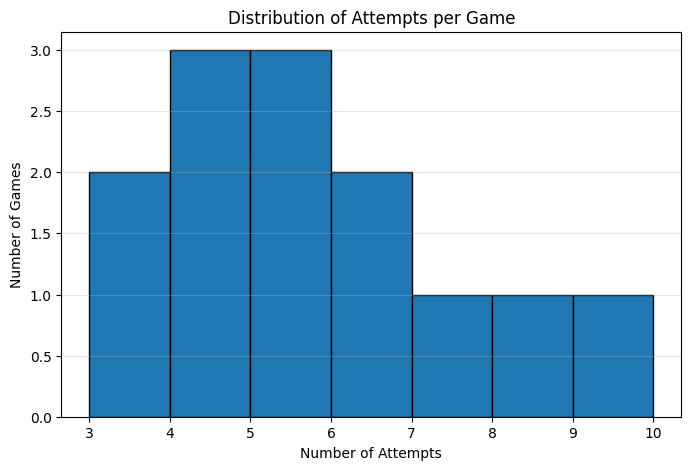

In [ ]:
attempt_distribution(df)

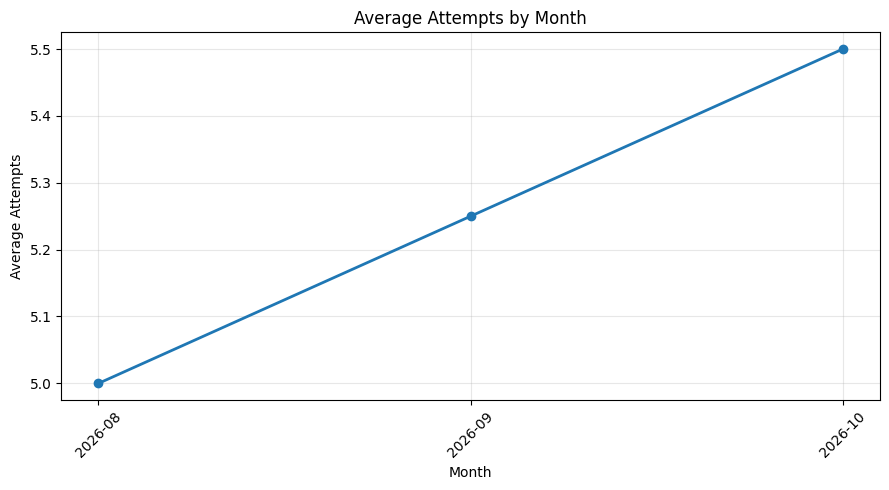

In [ ]:
monthly_attempts(df)

In [ ]:
print("PERFORMANCE PATTERN ANALYSIS")
print("=" * 60)

average_attempts = df["Attempts"].mean()

best_attempts = df["Attempts"].min()

worst_attempts = df["Attempts"].max()

success_rate = (
    (df["Result"].str.lower() == "success").mean()
    * 100
)

print(
    "Overall Average Attempts:",
    round(average_attempts, 2)
)

print(
    "Best Performance:",
    best_attempts,
    "attempts"
)

print(
    "Highest Attempts in a Game:",
    worst_attempts
)

print(
    "Overall Success Rate:",
    round(success_rate, 2),
    "%"
)

print("\nPATTERNS IDENTIFIED:")

if success_rate >= 70:
    print("• Players have a generally high success rate.")
else:
    print("• Players may need improvement in successful guessing.")

if average_attempts <= 5:
    print("• Players generally identify the number within a small number of attempts.")
else:
    print("• Players generally require more attempts to identify the number.")

if best_attempts <= 3:
    print("• Some games show very efficient guessing performance.")

if worst_attempts >= 8:
    print("• Some games require significantly more attempts.")

PERFORMANCE PATTERN ANALYSIS
Overall Average Attempts: 5.31
Best Performance: 3 attempts
Highest Attempts in a Game: 9
Overall Success Rate: 84.62 %

PATTERNS IDENTIFIED:
• Players have a generally high success rate.
• Players generally require more attempts to identify the number.
• Some games show very efficient guessing performance.
• Some games require significantly more attempts.


In [ ]:
print("BEFORE UPDATE")
display(load_games(CSV_FILE).head(1))

game_id = 1

updated = update_game(
    CSV_FILE,
    game_id,
    {"Score": 95}
)

print("\nUpdate successful:", updated)

print("\nAFTER UPDATE")
display(load_games(CSV_FILE).head(1))

BEFORE UPDATE


,Game_ID,Player,Date,Target,Attempts,Result,Score
0,1,Foram,2026-08-05,57,4,Success,70



Update successful: True

AFTER UPDATE


,Game_ID,Player,Date,Target,Attempts,Result,Score
0,1,Foram,2026-08-05,57,4,Success,95


In [ ]:
temp_record = {
    "Game_ID": 999,
    "Player": "TestPlayer",
    "Date": "2026-10-07",
    "Target": 50,
    "Attempts": 1,
    "Result": "Success",
    "Score": 100
}

save_game(
    CSV_FILE,
    temp_record
)

print("Temporary record added.")

deleted = delete_game(
    CSV_FILE,
    999
)

print("Delete successful:", deleted)

print("\nCurrent number of games:",
      len(load_games(CSV_FILE)))

Temporary record added.
Delete successful: True

Current number of games: 13


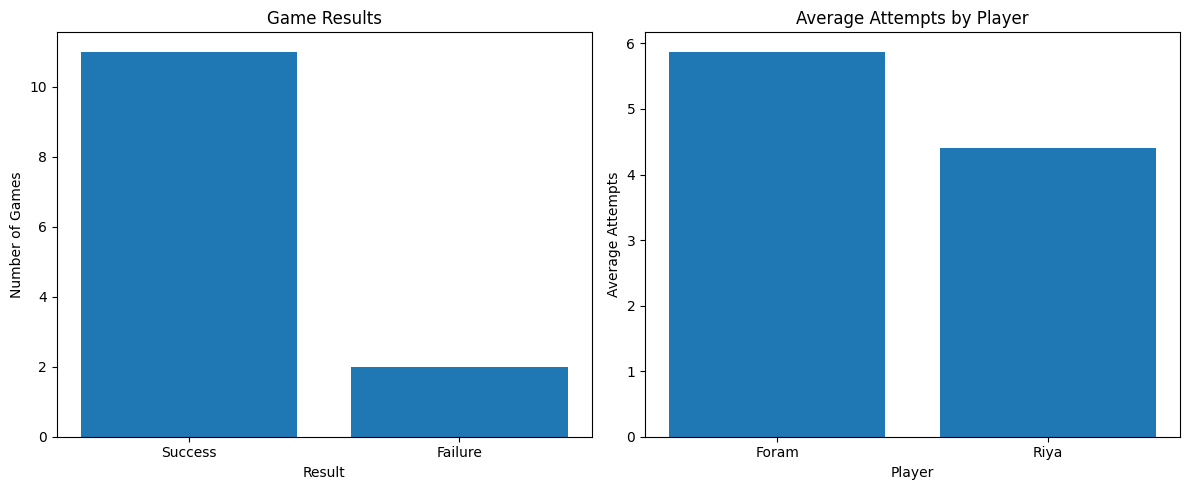


       NUMBER GUESSING GAME DASHBOARD
Total Games: 13
Successful Games: 11
Failed Games: 2
Success Rate: 84.62 %
Average Attempts: 5.31
Best Attempts: 3
Highest Attempts: 9


In [ ]:
import matplotlib.pyplot as plt

df = load_games(CSV_FILE)
stats = calculate_statistics(df)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Chart 1: Success vs Failure
result_counts = df["Result"].value_counts()

axes[0].bar(
    result_counts.index,
    result_counts.values
)

axes[0].set_title("Game Results")
axes[0].set_xlabel("Result")
axes[0].set_ylabel("Number of Games")

# Chart 2: Player Average Attempts
player_data = (
    df.groupby("Player")["Attempts"]
    .mean()
)

axes[1].bar(
    player_data.index,
    player_data.values
)

axes[1].set_title("Average Attempts by Player")
axes[1].set_xlabel("Player")
axes[1].set_ylabel("Average Attempts")

plt.tight_layout()
plt.show()

print("\n" + "=" * 60)
print("       NUMBER GUESSING GAME DASHBOARD")
print("=" * 60)

print("Total Games:", stats["Total Games"])
print("Successful Games:", stats["Successful Games"])
print("Failed Games:", stats["Failed Games"])
print("Success Rate:", stats["Success Rate"], "%")
print("Average Attempts:", stats["Average Attempts"])
print("Best Attempts:", stats["Minimum Attempts"])
print("Highest Attempts:", stats["Maximum Attempts"])
print("=" * 60)

In [ ]:
print("INPUT VALIDATION TEST")
print("=" * 50)

# Test 1: Invalid number
try:
    value = int("abc")
    print("Valid number:", value)

except ValueError:
    print("✓ Invalid number handled correctly")

# Test 2: Number outside allowed range
guess = 150

if guess < 1 or guess > 100:
    print("✓ Out-of-range guess rejected:", guess)

# Test 3: Valid number
guess = 57

if 1 <= guess <= 100:
    print("✓ Valid guess accepted:", guess)

INPUT VALIDATION TEST
✓ Invalid number handled correctly
✓ Out-of-range guess rejected: 150
✓ Valid guess accepted: 57


In [ ]:
print("=" * 60)
print("     FINAL PROJECT VERIFICATION")
print("=" * 60)

df = load_games(CSV_FILE)

print("\n✓ CSV file exists:", os.path.exists(CSV_FILE))
print("✓ Total game records:", len(df))
print("✓ Game engine loaded")
print("✓ Storage module loaded")
print("✓ Analytics module loaded")
print("✓ Reports module loaded")
print("✓ GUI module created")

stats = calculate_statistics(df)

print("\nFINAL STATISTICS")
print("-" * 40)

for key, value in stats.items():
    print(f"{key}: {value}")

print("\n" + "=" * 60)
print("PROJECT VERIFICATION COMPLETED SUCCESSFULLY!")
print("=" * 60)

     FINAL PROJECT VERIFICATION

✓ CSV file exists: True
✓ Total game records: 13
✓ Game engine loaded
✓ Storage module loaded
✓ Analytics module loaded
✓ Reports module loaded
✓ GUI module created

FINAL STATISTICS
----------------------------------------
Total Games: 13
Successful Games: 11
Failed Games: 2
Success Rate: 84.62
Average Attempts: 5.31
Minimum Attempts: 3
Maximum Attempts: 9
Average Successful Attempts: 4.73

PROJECT VERIFICATION COMPLETED SUCCESSFULLY!


In [ ]:
%%writefile README.md

# Number Guessing Game – History & Statistical Analysis

## Project Overview

This project is a Number Guessing Game combined with
history and statistical analysis.

The application records game attempts, success/failure,
scores, player information and dates.

The stored data is analyzed using Python, NumPy and Pandas,
and visual reports are generated using Matplotlib.

## Main Features

- Number guessing game
- Attempt counting
- Success and failure tracking
- Score calculation
- Persistent CSV storage
- Game history
- Search by player
- Filter by result
- Player comparison
- Monthly analysis
- NumPy statistical analysis
- Pattern identification
- Matplotlib visualizations
- Dashboard
- Update and delete operations
- Input validation
- Exception handling
- Tkinter GUI module

## Project Modules

### game_engine.py
Contains the main game logic, guess checking,
score calculation and game-record creation.

### storage.py
Handles CSV creation, loading, saving, updating
and deleting game records.

### analytics.py
Performs statistical analysis, player comparison,
searching, filtering and monthly analysis.

### reports.py
Creates graphical reports using Matplotlib.

### gui.py
Contains the Tkinter-based graphical user interface.

## Technologies Used

- Python
- NumPy
- Pandas
- Matplotlib
- Tkinter
- CSV File Handling
- Google Colab

## Data Storage

Game history is stored persistently in:

number_guessing_project/game_history.csv

## Visual Reports

The project generates:

1. Distribution of Attempts per Game
2. Average Attempts by Month
3. Game Results Dashboard
4. Average Attempts by Player

## Execution Environment

The data processing, game engine, storage,
analytics and visualization components were
executed in Google Colab.

The Tkinter GUI module is included in the project
and can be executed in a local Python environment.

## Conclusion

The project demonstrates how a simple number
guessing game can be extended into a data analysis
application by recording game history and using
statistical techniques to identify player and
performance patterns.

Writing README.md
